# A/B-тесты

Две части:
1. **Дизайн A/B-теста для магазина.** В воронке ([`03_funnel_retention.ipynb`](03_funnel_retention.ipynb)) больше всего людей теряется между просмотром и корзиной. Придумываю тест для этого шага и по реальным данным считаю, сколько людей и недель он займёт.
2. **Анализ готового A/B-теста Cookie Cats.** В мобильной игре проверяли, куда ставить «ворота» (паузу, после которой нужно подождать или заплатить): на 30-й уровень или на 40-й. Разбираю, можно ли доверять тесту и что он показал.

In [1]:
import duckdb
from pathlib import Path

# корень проекта: ноутбук может запускаться и из notebooks/, и из корня
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent

# read_only: базу можно читать одновременно из ноутбука и из терминала
con = duckdb.connect(str(ROOT / 'data/processed/shop.duckdb'), read_only=True)

def q(sql):
    """Выполнить SQL и показать результат таблицей."""
    return con.sql(sql).df()

In [2]:
import matplotlib.pyplot as plt
import numpy as np

FIG = ROOT / 'reports/figures'
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#1f1f1d', '#6b6a63', '#e1e0d9'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
})

import pandas as pd
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

rng = np.random.default_rng(42)

# Часть 1. Дизайн A/B-теста для магазина

## Гипотеза

**Если** на карточке товара показывать, сколько человек купили этот товар за последнюю неделю, **то** доля пользователей, которые кладут товар в корзину, вырастет, **потому что** 77% людей смотрят товары и уходят, ничего не положив в корзину: в косметике сложно выбрать, и подтверждение от других покупателей снижает сомнения.

## Метрики

| Тип | Метрика | Зачем |
|---|---|---|
| Основная | доля пользователей с добавлением в корзину среди тех, кто смотрел товары | на неё рассчитана гипотеза |
| Защитная | доля пользователей с покупкой среди тех, кто смотрел товары | рост корзин не должен оказаться пустыми добавлениями |
| Защитная | средний чек (по `price > 0`) | блок не должен смещать людей к дешёвым товарам |
| Защитная | доля удалений из корзины | если удалений станет больше, добавления были импульсивными |
| Проверка теста | соотношение групп (SRM) | если группы разъехались не 50/50, тесту доверять нельзя |

**Единица разбиения — пользователь (`user_id`).** Риск из очистки: иногда сайт выдаёт одному посетителю новый ID, и он может попасть в обе группы. Это редкий случай (128 сессий), но перед тестом стоит сообщить о нём тем, кто отвечает за запись событий.

## Базовая конверсия и её стабильность

Чтобы рассчитать тест, нужна текущая конверсия и то, насколько она колеблется от недели к неделе. Здесь считаю строго: среди тех, кто смотрел товары, — доля тех, кто положил товар в корзину и купил.

In [3]:
weekly = q("""
WITH users_by_week AS (
    SELECT
        DATE_TRUNC('week', event_time)::date AS week,
        user_id,
        MAX(CASE WHEN event_type = 'view'     THEN 1 ELSE 0 END) AS viewed,
        MAX(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) AS carted,
        MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
    FROM events_clean
    WHERE event_time >= '2019-12-16' AND event_time < '2020-01-27'
    GROUP BY ALL
)
SELECT
    week,
    SUM(viewed) AS viewers,
    ROUND(100.0 * SUM(viewed * carted)    / SUM(viewed), 2) AS view_to_cart_pct,
    ROUND(100.0 * SUM(viewed * purchased) / SUM(viewed), 2) AS view_to_purchase_pct
FROM users_by_week
GROUP BY week
ORDER BY week
""")
weekly

,week,viewers,view_to_cart_pct,view_to_purchase_pct
0,2019-12-16,98231.0,20.99,6.51
1,2019-12-23,90897.0,19.40,5.72
2,2019-12-30,79679.0,18.53,4.42
3,2020-01-06,109052.0,19.67,5.45
4,2020-01-13,111630.0,21.11,5.97
5,2020-01-20,106995.0,21.98,5.98


### Что видно

- **Конверсия в корзину заметно колеблется от недели к неделе:** в январе от 19,67% до 21,98%, в новогоднюю неделю 18,53%. Разница между обычными неделями больше 2 п.п.
- **Поэтому эффект нельзя оценить по принципу «до и после»**, сравнив неделю до запуска с неделей после: колебания между неделями больше, чем эффект, который я ищу. Нужна контрольная группа в то же самое время — это и есть A/B-тест.
- **В новогоднюю неделю конверсия ниже всего.** Тест не стоит запускать на праздниках: результат с праздников не перенесётся на обычные недели.

Для расчёта беру три обычные недели января (6–26 января): без праздников и без всплеска 27–28 января. Считаю, сколько уникальных людей смотрят товары за 1, 2 и 3 недели. За несколько недель людей меньше, чем сумма по неделям, потому что многие заходят повторно.

In [4]:
base = q("""
WITH viewers AS (
    SELECT user_id,
           MIN(event_time) AS first_view,
           MAX(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) AS carted,
           MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
    FROM events_clean
    WHERE event_time >= '2020-01-06' AND event_time < '2020-01-27'
    GROUP BY user_id
    HAVING MAX(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) = 1
)
SELECT
    COUNT(*)                                                   AS viewers_3w,
    SUM(CASE WHEN first_view < '2020-01-13' THEN 1 ELSE 0 END)  AS viewers_1w,
    SUM(CASE WHEN first_view < '2020-01-20' THEN 1 ELSE 0 END)  AS viewers_2w,
    ROUND(AVG(carted), 4)                                      AS p_cart,
    ROUND(AVG(purchased), 4)                                   AS p_purchase
FROM viewers
""")
base

,viewers_3w,viewers_1w,viewers_2w,p_cart,p_purchase
0,287927,109837.0,205089.0,0.2047,0.0639


## Размер выборки и длительность

**MDE** (минимальный эффект, который тест может заметить) — самое маленькое изменение метрики, которое я хочу уметь поймать. Чем меньше MDE, тем больше людей нужно.

Стандартные параметры: **α = 5%** (вероятность найти эффект, которого нет) и **мощность 80%** (вероятность найти эффект, если он есть). Считаю для нескольких MDE в относительных процентах.

In [5]:
p_cart, p_purchase = base.p_cart[0], base.p_purchase[0]
reach = {1: base.viewers_1w[0], 2: base.viewers_2w[0], 3: base.viewers_3w[0]}

def n_per_group(p, mde_rel, alpha=0.05, power=0.8):
    effect = proportion_effectsize(p * (1 + mde_rel), p)
    return int(np.ceil(NormalIndPower().solve_power(effect, alpha=alpha, power=power, ratio=1)))

def weeks_needed(n):
    for w, people in reach.items():
        if people >= 2 * n:
            return str(w)
    return 'больше 3'

rows = []
for metric, p in [('корзина (основная)', p_cart), ('покупка (защитная)', p_purchase)]:
    for mde in [0.02, 0.03, 0.05]:
        n = n_per_group(p, mde)
        rows.append({'metric': metric, 'baseline_pct': round(100 * p, 2), 'mde_rel_pct': int(mde * 100),
                     'mde_abs_pp': round(100 * p * mde, 2), 'n_per_group': n, 'n_total': 2 * n,
                     'weeks': weeks_needed(n)})
sizes = pd.DataFrame(rows)
sizes

,metric,baseline_pct,mde_rel_pct,mde_abs_pp,n_per_group,n_total,weeks
0,корзина (основная),20.47,2,0.41,153597,307194,больше 3
1,корзина (основная),20.47,3,0.61,68513,137026,2
2,корзина (основная),20.47,5,1.02,24842,49684,1
3,покупка (защитная),6.39,2,0.13,580247,1160494,больше 3
4,покупка (защитная),6.39,3,0.19,259069,518138,больше 3
5,покупка (защитная),6.39,5,0.32,94111,188222,2


### Что видно

- **Базовая конверсия в корзину за три недели — 20,47%, в покупку — 6,39%.** За одну неделю товары смотрят около 110 тысяч уникальных людей, за две — 205 тысяч, за три — 288 тысяч.
- **Для основной метрики выбираю MDE 3%:** с 20,47% до 21,08%, то есть +0,61 п.п. Для этого нужно 68 513 человек в каждой группе — 2 недели. MDE 2% потребовал бы больше трёх недель, а 5% — слишком грубо: эффект от одного блока на карточке вряд ли будет таким большим.
- **Защитную метрику (покупку) за 2 недели можно проверить только на падение от 5%** (0,32 п.п.): покупок мало, и для точности нужно намного больше людей. Это нужно сказать заранее: небольшое падение покупок тест не увидит.
- **Итог дизайна: 2 полные недели, 50/50, разбиение по `user_id`, без праздников и акций.** Тест не останавливаю раньше, даже если p-value уже стал меньше 0,05. Если подглядывать и останавливать при первом «значимом» результате, ложных находок будет намного больше 5%.

## A/A-тест на реальных данных

Перед настоящим тестом проверяю сам метод: делю реальных пользователей случайно на две группы, в которых ничего не меняли, и сравниваю их тем же z-тестом. Повторяю 2 000 раз. Если метод правильный, «значимая» разница должна находиться примерно в 5% случаев — это и есть α. Если чаще, тест будет находить эффекты, которых нет.

In [6]:
users = q("""
SELECT user_id,
       MAX(CASE WHEN event_type = 'cart' THEN 1 ELSE 0 END) AS carted
FROM events_clean
WHERE event_time >= '2020-01-06' AND event_time < '2020-01-20'
GROUP BY user_id
HAVING MAX(CASE WHEN event_type = 'view' THEN 1 ELSE 0 END) = 1
""")
y = users.carted.to_numpy()
n = len(y)

p_values = []
for _ in range(2000):
    in_b = rng.random(n) < 0.5
    counts = [y[~in_b].sum(), y[in_b].sum()]
    nobs = [(~in_b).sum(), in_b.sum()]
    p_values.append(proportions_ztest(counts, nobs)[1])
p_values = np.array(p_values)

print(f'пользователей в A/A: {n:,}'.replace(',', ' '))
print(f'доля «значимых» различий при α = 5%: {100 * (p_values < 0.05).mean():.1f}%')

пользователей в A/A: 204 454
доля «значимых» различий при α = 5%: 5.1%


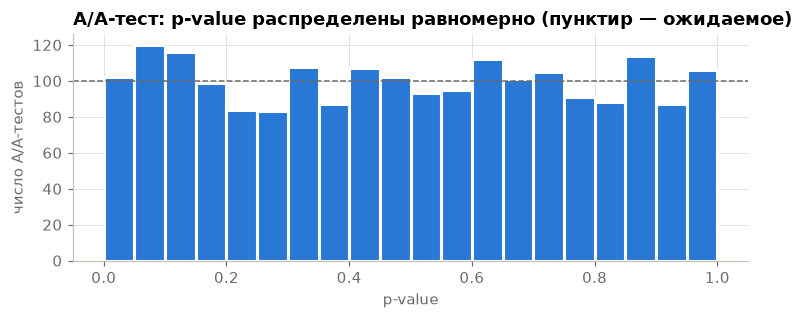

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(p_values, bins=20, range=(0, 1), color=BLUE, edgecolor='white', linewidth=2)
ax.axhline(len(p_values) / 20, color=MUTED, linestyle='--', linewidth=1)
ax.set_xlabel('p-value')
ax.set_ylabel('число A/A-тестов')
ax.set_title('A/A-тест: p-value распределены равномерно (пунктир — ожидаемое)')
plt.tight_layout()
plt.savefig(FIG / 'aa_test_pvalues.png', bbox_inches='tight')
plt.show()

### Что видно

- **В 2 000 A/A-тестах «значимая» разница нашлась в 5,1% случаев** — почти ровно α = 5%, и p-value распределены равномерно.
- Значит, z-тест на этой метрике работает правильно: разбиение по пользователям не создаёт ложных эффектов, и 5% ошибок — это действительно 5%.

# Часть 2. Анализ A/B-теста Cookie Cats

Каждая строка — игрок: `version` — группа (`gate_30` — контроль, ворота на 30-м уровне; `gate_40` — тест, на 40-м), `sum_gamerounds` — сколько раундов сыграл за первые 14 дней, `retention_1` и `retention_7` — вернулся ли через 1 и через 7 дней после установки.

In [8]:
cc = con.sql(f"SELECT * FROM read_csv_auto('{ROOT / 'data/raw/cookie_cats.csv'}')").df()
print(cc.shape)
cc.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Проверка данных и SRM

Сначала проверяю, что игроки не повторяются и что группы разделились 50/50 (SRM — sample ratio mismatch). Если соотношение групп заметно отличается от задуманного, значит, что-то сломалось в разбиении, и результатам доверять нельзя.

In [9]:
print('повторяющихся userid:', cc.userid.duplicated().sum())
print('пропусков:', int(cc.isna().sum().sum()))

groups = cc.version.value_counts().sort_index()
chi2, p_srm = stats.chisquare(groups.values)
print(groups.to_string())
print(f'доля gate_40: {100 * groups["gate_40"] / groups.sum():.2f}%,  p-value SRM = {p_srm:.3f}')

повторяющихся userid: 0
пропусков: 0
version
gate_30    44700
gate_40    45489
доля gate_40: 50.44%,  p-value SRM = 0.009


### Что видно

- **Повторов игроков и пропусков нет.**
- **Группы разделились не совсем поровну:** в `gate_40` 50,44% игроков, на 789 больше, чем в `gate_30`. Проверка SRM даёт p-value = 0,009.
- По обычному порогу 0,05 это подозрительно. Для SRM в компаниях часто берут более строгий порог 0,001, потому что эту проверку делают в каждом тесте, и по нему проблема не подтверждается. Точно сказать, сломано ли разбиение, я не могу, поэтому считаю результат дальше, но с этой оговоркой. В компании я бы уточнила у разработчиков, как распределяли игроков.

## Сколько раундов играют

In [10]:
cc.groupby('version').sum_gamerounds.describe(percentiles=[.25, .5, .75, .99]).round(1)

,count,mean,std,min,25%,50%,75%,99%,max
version,,,,,,,,,
gate_30,44700.0,52.5,256.7,0.0,5.0,17.0,50.0,493.0,49854.0
gate_40,45489.0,51.3,103.3,0.0,5.0,16.0,52.0,492.1,2640.0


In [11]:
print(f'медиана {cc.sum_gamerounds.median():.0f}, 99-й перцентиль {cc.sum_gamerounds.quantile(0.99):.0f}, максимум {cc.sum_gamerounds.max()}')
print('игроков с 0 раундов:', (cc.sum_gamerounds == 0).sum())
print(f'сыграли хотя бы 30 раундов: {100 * (cc.sum_gamerounds >= 30).mean():.1f}%')
print('Манн-Уитни по раундам, p-value =',
      round(stats.mannwhitneyu(cc.sum_gamerounds[cc.version == 'gate_30'],
                               cc.sum_gamerounds[cc.version == 'gate_40']).pvalue, 3))

медиана 16, 99-й перцентиль 493, максимум 49854
игроков с 0 раундов: 3994
сыграли хотя бы 30 раундов: 36.9%
Манн-Уитни по раундам, p-value = 0.05


### Что видно

- **Раунды распределены очень неравномерно.** Медиана 16, у 99% игроков меньше 493 раундов, а максимум — 49 854 (в `gate_30`). Из-за одного такого игрока среднее и разброс в `gate_30` сильно выше. Поэтому раунды сравниваю по медиане и тестом Манна-Уитни, а не по среднему.
- **3 994 игрока не сыграли ни одного раунда:** установили игру и не открыли её.
- **Хотя бы 30 раундов сыграли только 36,9% игроков.** Ворота стоят на 30-м или 40-м уровне, поэтому большинство игроков их вообще не увидели, и для них группы ничем не отличаются. Это размывает эффект.
- **Отбирать только тех, кто сыграл 30+ раундов, нельзя:** число раундов само зависит от того, где стоят ворота. После такого отбора группы стали бы несравнимыми.
- **По раундам группы почти не отличаются:** p-value = 0,05, на границе.

## Удержание по группам

In [12]:
summary = cc.groupby('version').agg(
    players=('userid', 'count'),
    retention_1_pct=('retention_1', 'mean'),
    retention_7_pct=('retention_7', 'mean'),
)
summary[['retention_1_pct', 'retention_7_pct']] = (100 * summary[['retention_1_pct', 'retention_7_pct']]).round(2)
summary

,players,retention_1_pct,retention_7_pct
version,,,
gate_30,44700,44.82,19.02
gate_40,45489,44.23,18.20


In [13]:
for metric in ['retention_1', 'retention_7']:
    g = cc.groupby('version')[metric]
    counts = g.sum().loc[['gate_40', 'gate_30']].values
    nobs = g.count().loc[['gate_40', 'gate_30']].values
    diff = 100 * (counts[0] / nobs[0] - counts[1] / nobs[1])
    z, p = proportions_ztest(counts, nobs)
    print(f'{metric}: gate_40 − gate_30 = {diff:+.2f} п.п., z = {z:.2f}, p-value = {p:.4f}')

retention_1: gate_40 − gate_30 = -0.59 п.п., z = -1.78, p-value = 0.0744


retention_7: gate_40 − gate_30 = -0.82 п.п., z = -3.16, p-value = 0.0016


### Что видно

- **Через 1 день** в `gate_40` возвращаются 44,23% против 44,82% — на 0,59 п.п. меньше. Но p-value = 0,074, и это может быть случайностью.
- **Через 7 дней** — 18,20% против 19,02%, на 0,82 п.п. меньше, p-value = 0,0016. Эта разница значимая.

## Бутстрап

Z-тест опирается на формулу. Бутстрап проверяет то же самое без формул: 5 000 раз случайно пересобираю каждую группу из её же игроков (с повторениями) и смотрю, как меняется разница удержания. Получаю распределение разницы и 95%-й доверительный интервал.

In [14]:
a = cc[cc.version == 'gate_30']
b = cc[cc.version == 'gate_40']
boot = {}
for metric in ['retention_1', 'retention_7']:
    xa, xb = a[metric].to_numpy(), b[metric].to_numpy()
    means_a = np.array([rng.choice(xa, len(xa)).mean() for _ in range(5000)])
    means_b = np.array([rng.choice(xb, len(xb)).mean() for _ in range(5000)])
    boot[metric] = 100 * (means_b - means_a)

ci = pd.DataFrame({m: {'diff_pp': round(100 * (b[m].mean() - a[m].mean()), 2),
                       'ci_low_pp': round(np.percentile(d, 2.5), 2),
                       'ci_high_pp': round(np.percentile(d, 97.5), 2),
                       'share_below_zero_pct': round(100 * (d < 0).mean(), 1)}
                   for m, d in boot.items()}).T
ci

,diff_pp,ci_low_pp,ci_high_pp,share_below_zero_pct
retention_1,-0.59,-1.25,0.06,96.5
retention_7,-0.82,-1.34,-0.30,99.9


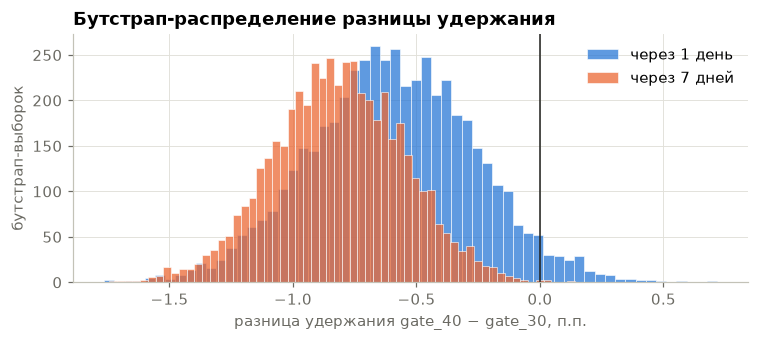

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for metric, color, label in [('retention_1', BLUE, 'через 1 день'), ('retention_7', ORANGE, 'через 7 дней')]:
    ax.hist(boot[metric], bins=60, color=color, alpha=0.75, label=label, edgecolor='white', linewidth=0.5)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel('разница удержания gate_40 − gate_30, п.п.')
ax.set_ylabel('бутстрап-выборок')
ax.set_title('Бутстрап-распределение разницы удержания')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / 'cookie_cats_bootstrap.png', bbox_inches='tight')
plt.show()

### Что видно

- **Удержание на 7-й день:** 95%-й интервал разницы — от −1,34 до −0,30 п.п., он целиком ниже нуля. В 99,9% бутстрап-выборок `gate_40` хуже.
- **Удержание на 1-й день:** интервал от −1,25 до +0,06 п.п. задевает ноль. Это совпадает с z-тестом: разница может быть случайной.
- **Бутстрап и z-тест дали одинаковый ответ,** значит, вывод не зависит от метода.

## Мощность: какой эффект этот тест вообще мог заметить

In [16]:
n_group = int(groups.min())
h = NormalIndPower().solve_power(nobs1=n_group, alpha=0.05, power=0.8, ratio=1)
for metric in ['retention_1', 'retention_7']:
    p0 = a[metric].mean()
    p1 = np.sin(np.arcsin(np.sqrt(p0)) - h / 2) ** 2   # переводим размер эффекта h обратно в долю
    print(f'{metric}: контроль {100 * p0:.2f}%, MDE при мощности 80% ≈ {100 * (p0 - p1):.2f} п.п.')

retention_1: контроль 44.82%, MDE при мощности 80% ≈ 0.93 п.п.
retention_7: контроль 19.02%, MDE при мощности 80% ≈ 0.73 п.п.


### Что видно

- **Тест мог уверенно заметить разницу от 0,93 п.п. на 1-й день и от 0,73 п.п. на 7-й день** (при мощности 80%).
- **Разница на 7-й день (0,82 п.п.) больше этого порога** — эффект найден надёжно.
- **Разница на 1-й день (0,59 п.п.) меньше порога:** для такого эффекта тест был недостаточно чувствительным. Поэтому «нет значимой разницы» на 1-й день не значит «разницы нет» — тест просто не мог её уверенно увидеть.

# Итог

**Магазин.** Для шага «просмотр → корзина» предлагаю тест: блок «купили за неделю» на карточке товара. 2 полные недели, 50/50 по `user_id`, основная метрика — конверсия в корзину (MDE 3%, +0,61 п.п.), защитные — конверсия в покупку, средний чек и доля удалений из корзины. Сравнивать «до и после» нельзя: конверсия сама колеблется между неделями больше чем на 2 п.п. A/A-тест на реальных данных подтвердил, что метод даёт около 5% ложных находок, как и должен.

**Cookie Cats.** Ворота на 40-м уровне снижают удержание на 7-й день на 0,82 п.п.: с 19,02% до 18,20%, p-value = 0,0016, 95%-й интервал от −1,34 до −0,30 п.п. На 1-й день разница тоже отрицательная, но тест недостаточно чувствителен, чтобы её подтвердить.

**Рекомендация: оставить ворота на 30-м уровне.** Можно предположить, что ранняя пауза даёт отдохнуть от игры, и люди охотнее возвращаются; по данным это проверить нельзя.

Оговорки:
- группы разделились 50,44 / 49,56 (p-value SRM = 0,009) — стоит проверить, как распределяли игроков;
- большинство игроков (63%) не дошли до 30 раундов и ворота не увидели, поэтому эффект на тех, кто их увидел, больше, чем в среднем по тесту;
- удержание — не выручка: тест не показывает, как перенос ворот влияет на покупки в игре.